# Laboratorio 1 · Rischio, rendimento e frontiera efficiente

*Finanza Aziendale e Finanziamenti d'Impresa · A.A. 2026/27 · Laboratorio 1*

Abbiamo dei risparmi da investire in azioni italiane. Quali titoli scegliamo, e quanto di ciascuno? Oggi, con dieci anni di prezzi di nove titoli del FTSE MIB, misuriamo rendimento e rischio di un titolo, vediamo cosa succede quando ne mettiamo insieme due e poi tutti e nove, fino alla frontiera efficiente. In fondo, due parti facoltative: se il portafoglio migliore resta il migliore, e il beta.

> **Per salvare il tuo lavoro scarica il notebook:** File → Scarica → Scarica .ipynb. Il file scaricato è tuo: per riaprirlo, su Colab File → Carica notebook, e da lì Salva funziona normalmente. Se hai aperto il notebook dal sito con *Apri in Colab*, non usare Salva: Colab proverebbe a salvarlo su GitHub.

## 1 · I pacchetti e i dati

In [1]:
import polars as pl
from plotnine import *
import random #numeri casuali: serve dalla parte 8, per estrarre i pesi dei portafogli

In [2]:
#prezzi di fine mese da Yahoo Finance, novembre 2016 - ottobre 2026
#nove titoli del FTSE MIB e l'indice; i prezzi dei titoli tengono conto dei dividendi
prezzi = pl.read_csv("https://www.vincnardelli.com/msd/dati/ftsemib.csv", try_parse_dates=True) #try_parse_dates legge la colonna data come una data
prezzi.head()

data,TERNA,ENEL,GENERALI,ENI,FERRARI,INTESA,UNICREDIT,LEONARDO,STELLANTIS,FTSEMIB
date,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2016-11-01,2.6773,2.2345,6.8803,7.1134,47.8737,1.0306,7.1043,10.8254,3.6003,16930.0
2016-12-01,2.8474,2.4536,8.1502,8.3748,51.2072,1.1929,9.6059,11.7886,4.2794,19235.0
2017-01-01,2.655,2.3141,8.508,7.6927,53.4296,1.067,8.8399,10.5338,4.9881,18591.0
2017-02-01,2.8605,2.4267,7.8039,7.8605,56.9484,1.0818,8.8692,11.4616,5.1016,18913.0
2017-03-01,3.0423,2.6435,8.6004,8.3098,64.5878,1.2519,10.1312,11.7444,5.0621,20493.0


In [3]:
prezzi.shape #120 mesi, 11 colonne: la data, nove titoli e l'indice

(120, 11)

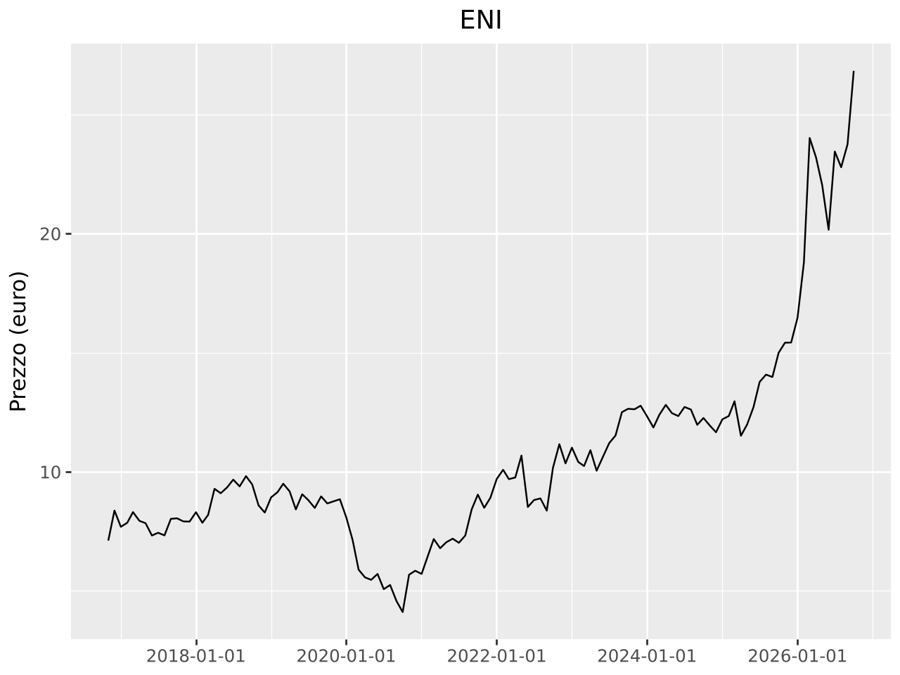

In [4]:
#un'azione ENI: 7,11 euro a novembre 2016, 26,83 a ottobre 2026
ggplot(prezzi, aes(x="data", y="ENI"))+geom_line()+labs(x="", y="Prezzo (euro)", title="ENI")

## 2 · Dai prezzi ai rendimenti

Il prezzo da solo non dice se un titolo è andato bene: conta di quanto è cambiato. Il rendimento del mese è la variazione percentuale del prezzo rispetto al mese prima:

$$r_t = \frac{P_t - P_{t-1}}{P_{t-1}}$$

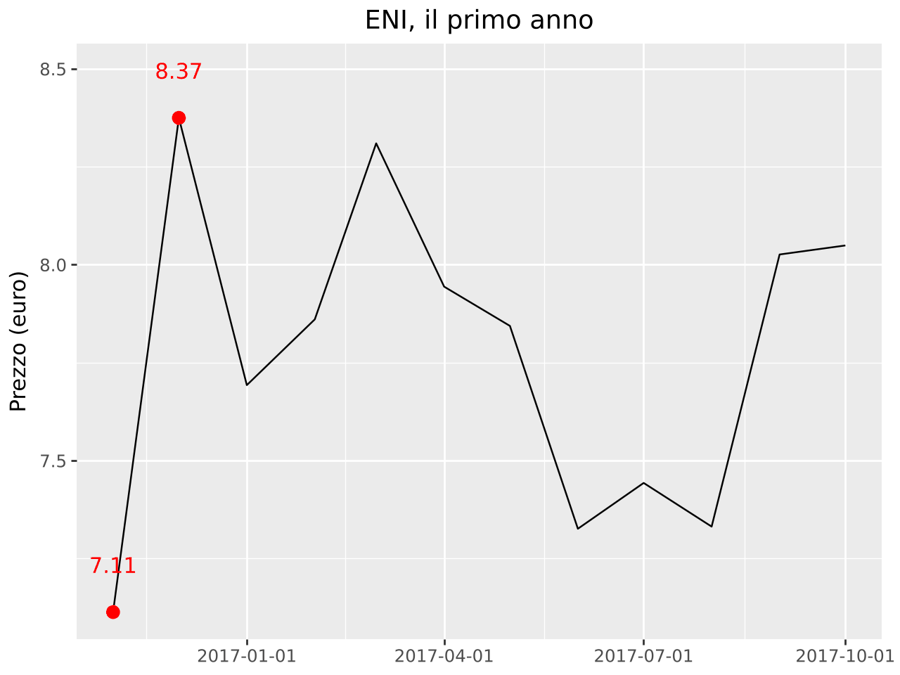

In [5]:
#il primo anno di ENI, con i primi due mesi in rosso: 7,11 a novembre 2016 e 8,37 a dicembre
#il rendimento di dicembre è (8,37 - 7,11) / 7,11 = 0,177, cioè +17,7%
primi_due = prezzi.head(2)
ggplot(prezzi.head(12), aes(x="data", y="ENI"))+geom_line()+geom_point(data=primi_due, color="red", size=3)+geom_text(aes(label="ENI"), data=primi_due, format_string="{:.2f}", color="red", nudge_y=0.12)+labs(x="", y="Prezzo (euro)", title="ENI, il primo anno")

In [6]:
#pct_change fa questa formula su tutta la colonna. Il primo mese è null: non c'è un mese prima
prezzi.select("data", "ENI").with_columns(rendimento=pl.col("ENI").pct_change()).head()

data,ENI,rendimento
date,f64,f64
2016-11-01,7.1134,null
2016-12-01,8.3748,0.177327
2017-01-01,7.6927,-0.081447
2017-02-01,7.8605,0.021813
2017-03-01,8.3098,0.057159


In [7]:
#lo stesso per tutte le colonne tranne la data; drop_nulls toglie la prima riga, che è vuota
rendimenti = prezzi.with_columns(pl.exclude("data").pct_change()).drop_nulls()
rendimenti.head()

data,TERNA,ENEL,GENERALI,ENI,FERRARI,INTESA,UNICREDIT,LEONARDO,STELLANTIS,FTSEMIB
date,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2016-12-01,0.063534,0.098053,0.18457,0.177327,0.069631,0.157481,0.352125,0.088976,0.188623,0.136149
2017-01-01,-0.06757,-0.056855,0.043901,-0.081447,0.0434,-0.105541,-0.079743,-0.106442,0.165607,-0.033481
2017-02-01,0.077401,0.048658,-0.082757,0.021813,0.065859,0.013871,0.003315,0.088078,0.022754,0.01732
2017-03-01,0.063555,0.089339,0.102064,0.057159,0.134146,0.157238,0.14229,0.024674,-0.007743,0.08354
2017-04-01,-0.004273,-0.011311,-0.024836,-0.04402,-0.000514,0.050324,0.033905,0.085777,0.01367,0.00566


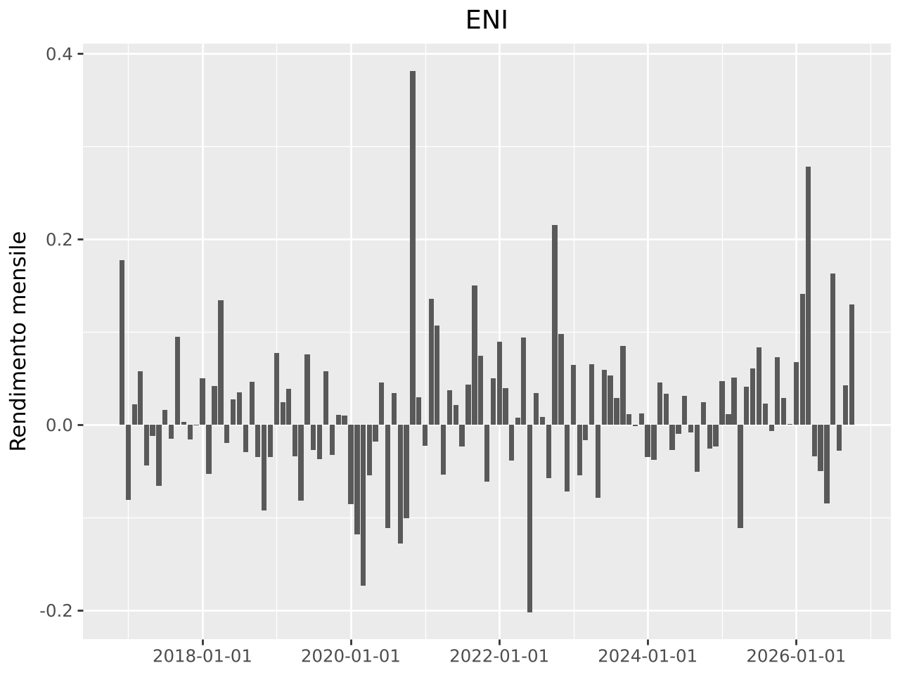

In [8]:
#i rendimenti vanno su e giù intorno allo zero
ggplot(rendimenti, aes(x="data", y="ENI"))+geom_col()+labs(x="", y="Rendimento mensile", title="ENI")

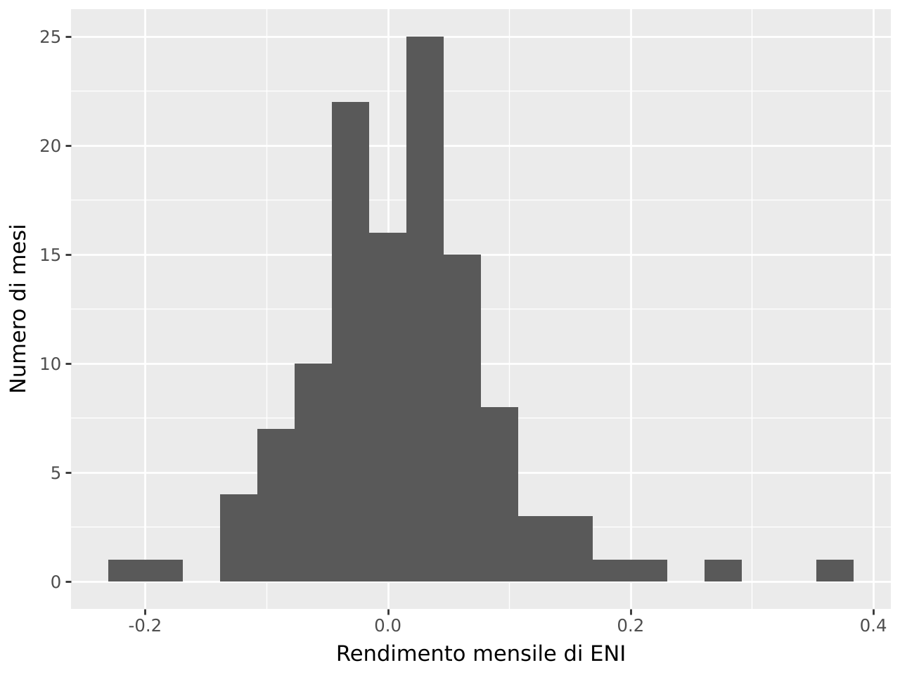

In [9]:
#nove mesi su dieci stanno tra -10% e +15%: il peggiore -20%, il migliore +38%
ggplot(rendimenti, aes(x="ENI"))+geom_histogram(bins=20)+labs(x="Rendimento mensile di ENI", y="Numero di mesi")

In [10]:
#dai rendimenti si torna al valore: 1.000 euro investiti a novembre 2016, mese dopo mese
#ogni mese il valore si moltiplica per (1 + rendimento); cum_prod fa il prodotto cumulato
valore = rendimenti.select("data", valore=1000*(1+pl.col("ENI")).cum_prod())
valore.tail(1) #a ottobre 2026 i 1.000 euro sono diventati 3.772

data,valore
date,f64
2026-10-01,3771.993702


## 3 · Rendimento atteso e rischio

Due numeri riassumono un titolo: la **media** dei rendimenti (quanto rende) e la **deviazione standard** (quanto oscilla intorno alla media: il rischio).

In [11]:
rendimenti["ENI"].mean() #in media +1,44% al mese

0.014359049739208495

In [12]:
rendimenti["ENI"].std() #deviazione standard 8,15% al mese

0.08152535422930653

In [13]:
#per parlare di un anno: la media si moltiplica per 12
rendimenti["ENI"].mean()*12 #17,2% l'anno

0.17230859687050193

In [14]:
#la deviazione standard si moltiplica per la radice di 12 (12**0.5)
rendimenti["ENI"].std()*12**0.5 #28,2% l'anno

0.2824121112604183

In [15]:
#per farlo su tutti i titoli serve una tabella "lunga": una riga per ogni mese e ogni titolo
lungo = rendimenti.unpivot(index="data", variable_name="titolo", value_name="rendimento")
lungo.head()

data,titolo,rendimento
date,str,f64
2016-12-01,"""TERNA""",0.063534
2017-01-01,"""TERNA""",-0.06757
2017-02-01,"""TERNA""",0.077401
2017-03-01,"""TERNA""",0.063555
2017-04-01,"""TERNA""",-0.004273


In [16]:
#media e deviazione standard di ogni titolo, già annuali, dal meno al più rischioso
#Terna è il più tranquillo (16,2%), Stellantis il più rischioso (39,9%) ed è anche quello che rende meno (9,6%)
titoli = lungo.group_by("titolo").agg(rendimento=pl.col("rendimento").mean()*12, rischio=pl.col("rendimento").std()*12**0.5).sort("rischio")
titoli

titolo,rendimento,rischio
str,f64,f64
"""TERNA""",0.141094,0.161929
"""FTSEMIB""",0.126397,0.188509
"""GENERALI""",0.207645,0.214474
"""ENEL""",0.168038,0.216747
"""FERRARI""",0.238071,0.266665
"""ENI""",0.172309,0.282412
"""INTESA""",0.218502,0.300703
"""UNICREDIT""",0.307036,0.38583
"""LEONARDO""",0.23268,0.38815


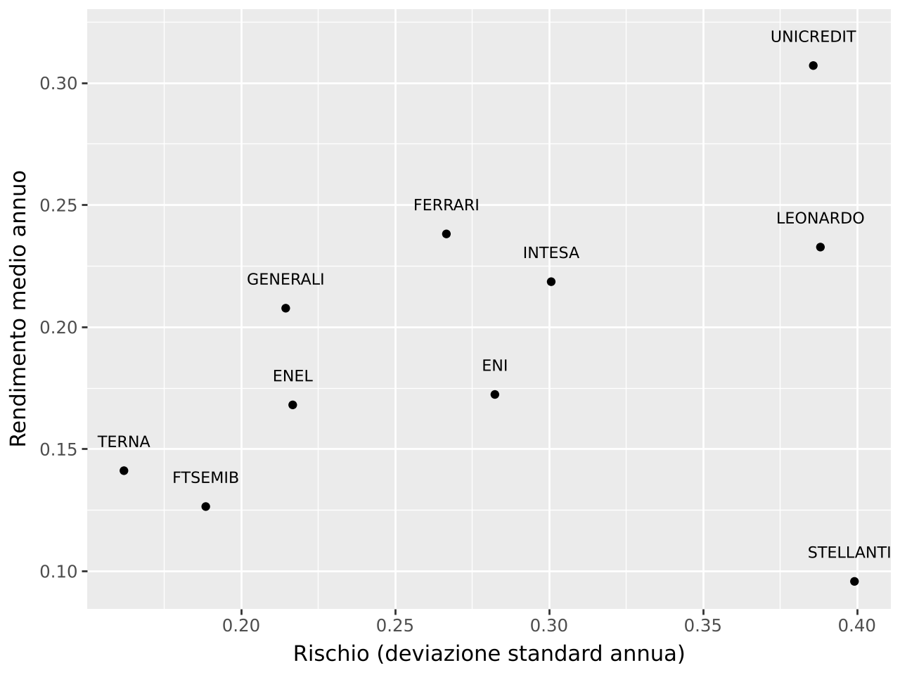

In [17]:
#ogni titolo è un punto: a destra più rischio, in alto più rendimento
#più rischio non vuol dire per forza più rendimento: Stellantis rischia più del doppio di Terna e rende meno
ggplot(titoli, aes(x="rischio", y="rendimento", label="titolo"))+geom_point()+geom_text(nudge_y=0.012, size=8)+labs(x="Rischio (deviazione standard annua)", y="Rendimento medio annuo")

## 4 · I titoli si muovono insieme? La correlazione

La correlazione misura quanto due titoli si muovono insieme. È la covarianza divisa per il prodotto delle due deviazioni standard, e va da −1 a 1:

$$\rho_{1,2} = \frac{\text{cov}(r_1, r_2)}{\sigma_1\,\sigma_2}$$

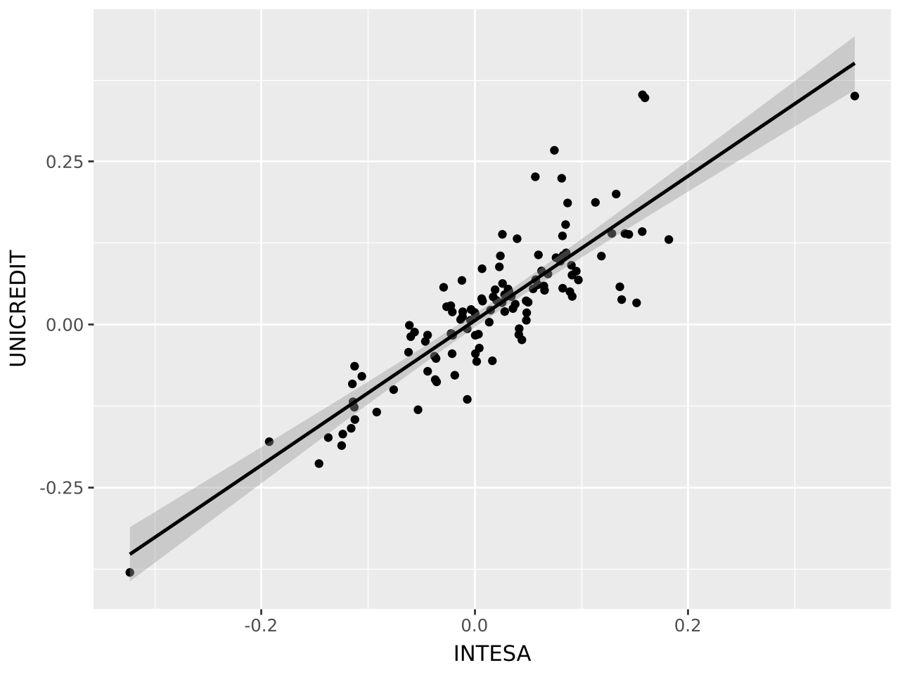

In [18]:
#due banche: quando sale una sale anche l'altra
ggplot(rendimenti, aes(x="INTESA", y="UNICREDIT"))+geom_point()+geom_smooth(method="lm")

In [19]:
rendimenti.select(pl.corr("INTESA", "UNICREDIT")) #correlazione 0,86: molto alta

INTESA
f64
0.864336


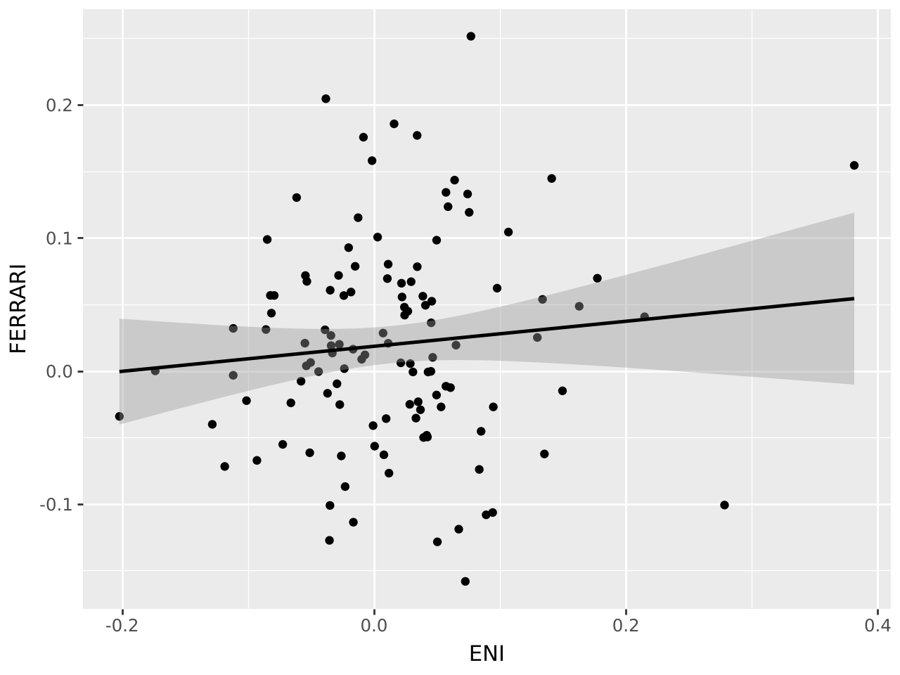

In [20]:
#petrolio e auto di lusso: la nuvola non ha una direzione
ggplot(rendimenti, aes(x="ENI", y="FERRARI"))+geom_point()+geom_smooth(method="lm")

In [21]:
rendimenti.select(pl.corr("ENI", "FERRARI")) #correlazione 0,10: quasi zero

ENI
f64
0.099522


In [22]:
#la stessa cosa con la formula: covarianza diviso il prodotto delle deviazioni standard. Torna 0,10
rendimenti.select(pl.cov("ENI", "FERRARI")).item()/(rendimenti["ENI"].std()*rendimenti["FERRARI"].std())

0.09952198020984887

In [23]:
#la matrice di correlazione: ogni colonna con tutte le altre (le righe sono nello stesso ordine delle colonne)
#sono tutte positive: tra 0,09 (Terna e Stellantis) e 0,86 (le due banche)
rendimenti.select("TERNA", "ENEL", "GENERALI", "ENI", "FERRARI", "INTESA", "UNICREDIT", "LEONARDO", "STELLANTIS").corr()

TERNA,ENEL,GENERALI,ENI,FERRARI,INTESA,UNICREDIT,LEONARDO,STELLANTIS
f64,f64,f64,f64,f64,f64,f64,f64,f64
1.0,0.755277,0.384511,0.272684,0.298875,0.299689,0.237553,0.24577,0.087936
0.755277,1.0,0.474778,0.392087,0.242253,0.567362,0.441693,0.335636,0.270409
0.384511,0.474778,1.0,0.503448,0.265923,0.730341,0.68245,0.496886,0.438232
0.272684,0.392087,0.503448,1.0,0.099522,0.516074,0.471347,0.505472,0.329027
0.298875,0.242253,0.265923,0.099522,1.0,0.217161,0.212756,0.20544,0.295528
0.299689,0.567362,0.730341,0.516074,0.217161,1.0,0.864336,0.476022,0.439369
0.237553,0.441693,0.68245,0.471347,0.212756,0.864336,1.0,0.432789,0.422973
0.24577,0.335636,0.496886,0.505472,0.20544,0.476022,0.432789,1.0,0.302949
0.087936,0.270409,0.438232,0.329027,0.295528,0.439369,0.422973,0.302949,1.0


## 5 · Un portafoglio di due titoli

Metà dei soldi in ENI e metà in Ferrari. Ogni mese il rendimento del portafoglio è la media dei due rendimenti, pesata con le quote investite.

In [24]:
due = rendimenti.with_columns(portafoglio=0.5*pl.col("ENI")+0.5*pl.col("FERRARI"))
due.select("data", "ENI", "FERRARI", "portafoglio").head()

data,ENI,FERRARI,portafoglio
date,f64,f64,f64
2016-12-01,0.177327,0.069631,0.123479
2017-01-01,-0.081447,0.0434,-0.019023
2017-02-01,0.021813,0.065859,0.043836
2017-03-01,0.057159,0.134146,0.095653
2017-04-01,-0.04402,-0.000514,-0.022267


In [25]:
#rendimento 20,5%: esattamente a metà tra ENI (17,2%) e Ferrari (23,8%)
due["portafoglio"].mean()*12

0.20518973526352224

In [26]:
#rischio 20,4%: molto meno di ENI (28,2%) e di Ferrari (26,7%)
#quando ENI va male Ferrari spesso no, e le oscillazioni si compensano: è la diversificazione
due["portafoglio"].std()*12**0.5

0.20362750494913526

In [27]:
#stesso esercizio con le due banche: metà Intesa, metà Unicredit
#rischio 33,2%: quasi la media dei due rischi (30,1% e 38,6%). Si muovono insieme, non si compensano
banche = rendimenti.with_columns(portafoglio=0.5*pl.col("INTESA")+0.5*pl.col("UNICREDIT"))
banche["portafoglio"].std()*12**0.5

0.3316049774148823

## 6 · Il ribilanciamento

Scrivere `0.5*ENI + 0.5*FERRARI` in ogni mese vuol dire che a ogni fine mese il portafoglio torna a metà e metà: si vende un po' del titolo salito di più e si compra l'altro. Si chiama **ribilanciare**. E se invece compriamo 500 euro di ciascuno e non tocchiamo più niente?

In [28]:
#500 euro in ENI e 500 in Ferrari a novembre 2016, lasciati crescere ognuno per conto suo
senza = rendimenti.select("data", eni=500*(1+pl.col("ENI")).cum_prod(), ferrari=500*(1+pl.col("FERRARI")).cum_prod())
senza.tail(1) #a ottobre 2026: 1.886 euro in ENI e 3.709 in Ferrari

data,eni,ferrari
date,f64,f64
2026-10-01,1885.996851,3708.716895


In [29]:
#il peso di Ferrari nel portafoglio, mese per mese
senza = senza.with_columns(peso_ferrari=pl.col("ferrari")/(pl.col("eni")+pl.col("ferrari")))
senza.tail(1) #alla fine Ferrari pesa il 66%, non più il 50%

data,eni,ferrari,peso_ferrari
date,f64,f64,f64
2026-10-01,1885.996851,3708.716895,0.662897


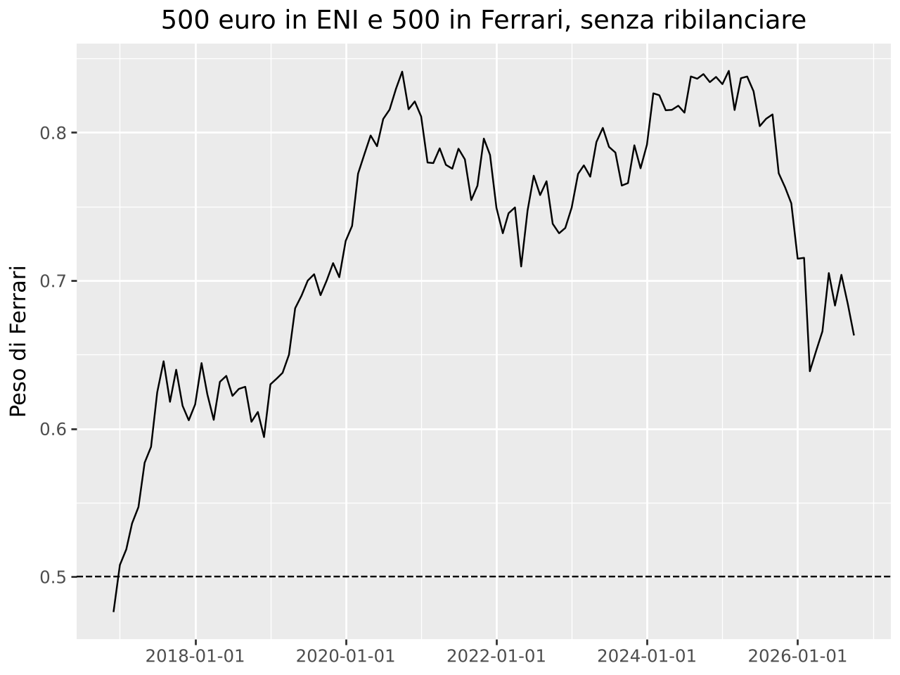

In [30]:
#la linea tratteggiata è il 50% di partenza: senza ribilanciare Ferrari è arrivata a pesare l'84%
ggplot(senza, aes(x="data", y="peso_ferrari"))+geom_line()+geom_hline(yintercept=0.5, linetype="dashed")+labs(x="", y="Peso di Ferrari", title="500 euro in ENI e 500 in Ferrari, senza ribilanciare")

In [31]:
#il rischio del portafoglio lasciato andare: 21,4%, contro il 20,4% di quello ribilanciato
#non è più il portafoglio che avevamo scelto: è diventato soprattutto Ferrari
senza.with_columns(totale=pl.col("eni")+pl.col("ferrari")).with_columns(rendimento=pl.col("totale").pct_change())["rendimento"].std()*12**0.5

0.21386521862167523

## 7 · E con altri pesi?

Con $w$ la quota nel primo titolo e $1-w$ nel secondo, rendimento e rischio del portafoglio sono:

$$\mu_p = w\,\mu_1 + (1-w)\,\mu_2 \qquad \sigma_p = \sqrt{w^2\sigma_1^2 + (1-w)^2\sigma_2^2 + 2\,w\,(1-w)\,\rho\,\sigma_1\sigma_2}$$

Servono solo cinque numeri: rendimento e rischio dei due titoli e la loro correlazione $\rho$.

In [32]:
m_1 = rendimenti["ENI"].mean()*12
s_1 = rendimenti["ENI"].std()*12**0.5
m_2 = rendimenti["FERRARI"].mean()*12
s_2 = rendimenti["FERRARI"].std()*12**0.5
rho = rendimenti.select(pl.corr("ENI", "FERRARI")).item() #item() tira fuori il numero dalla tabella

In [33]:
#w è la quota nel primo titolo (ENI), da 0 a 1 a passi di 0,01; il resto (1-w) va nel secondo (Ferrari)
pesi_w = pl.DataFrame({"w": range(0, 101)}).with_columns(w=pl.col("w")/100)
pesi_w.head()

w
f64
0.0
0.01
0.02
0.03
0.04


In [34]:
#le due formule, per ognuno dei 101 pesi
curva = pesi_w.with_columns(
    rendimento=pl.col("w")*m_1+(1-pl.col("w"))*m_2,
    rischio=((pl.col("w")*s_1)**2+((1-pl.col("w"))*s_2)**2+2*pl.col("w")*(1-pl.col("w"))*rho*s_1*s_2).sqrt()
)
curva.head()

w,rendimento,rischio
f64,f64,f64
0.0,0.238071,0.266665
0.01,0.237413,0.264294
0.02,0.236756,0.261954
0.03,0.236098,0.259645
0.04,0.23544,0.257368


In [35]:
#il portafoglio con il rischio più basso: 47% ENI e 53% Ferrari, rischio 20,3%, rendimento 20,7%
curva.sort("rischio").head(1)

w,rendimento,rischio
f64,f64,f64
0.47,0.207163,0.203291


In [36]:
#la stessa curva per le due banche: cambiano solo i cinque numeri
m_1 = rendimenti["INTESA"].mean()*12
s_1 = rendimenti["INTESA"].std()*12**0.5
m_2 = rendimenti["UNICREDIT"].mean()*12
s_2 = rendimenti["UNICREDIT"].std()*12**0.5
rho = rendimenti.select(pl.corr("INTESA", "UNICREDIT")).item()
curva_banche = pesi_w.with_columns(
    rendimento=pl.col("w")*m_1+(1-pl.col("w"))*m_2,
    rischio=((pl.col("w")*s_1)**2+((1-pl.col("w"))*s_2)**2+2*pl.col("w")*(1-pl.col("w"))*rho*s_1*s_2).sqrt()
)

In [37]:
#il rischio più basso è con w = 1: tutto Intesa. Aggiungere Unicredit non riduce mai il rischio
curva_banche.sort("rischio").head(1)

w,rendimento,rischio
f64,f64,f64
1.0,0.218502,0.300703


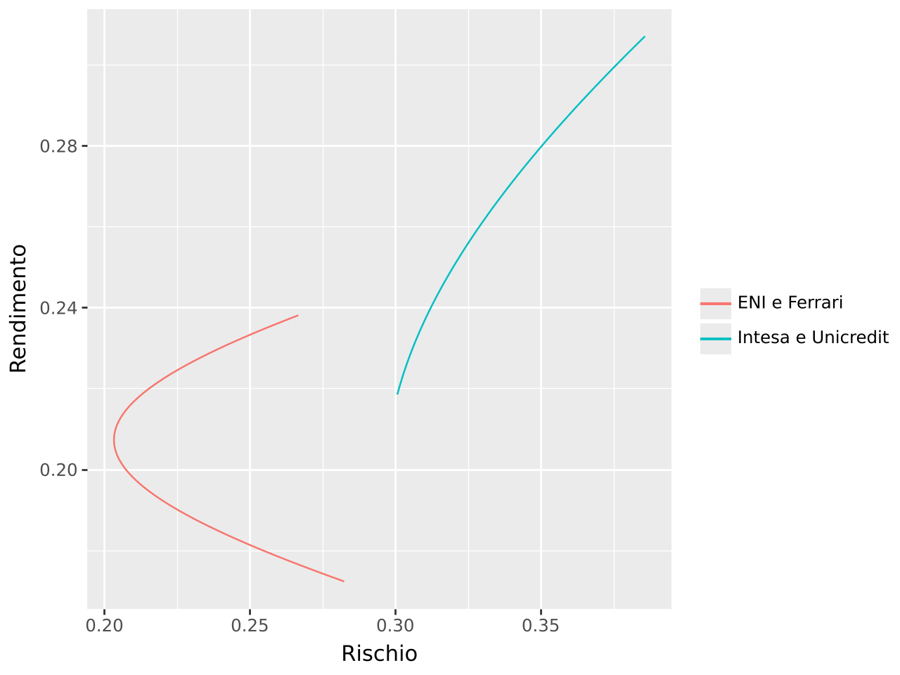

In [38]:
#le due curve insieme: una colonna dice di quale coppia si tratta, concat le mette una sotto l'altra
#geom_path unisce i punti nell'ordine della tabella, cioè al crescere di w
#ENI e Ferrari (correlazione 0,10) piega a sinistra; le banche (0,86) no: il rischio scende solo togliendo Unicredit
curve = pl.concat([curva.with_columns(coppia=pl.lit("ENI e Ferrari")), curva_banche.with_columns(coppia=pl.lit("Intesa e Unicredit"))])
ggplot(curve, aes(x="rischio", y="rendimento", color="coppia"))+geom_path()+labs(x="Rischio", y="Rendimento", color="")

Il rendimento di un portafoglio è la media dei rendimenti dei titoli; il rischio è meno della media dei rischi, e tanto meno quanto più bassa è la correlazione. E con nove titoli?

## 8 · Tanti titoli: i portafogli casuali

Con nove titoli le combinazioni di pesi sono infinite e la formula del rischio diventa lunga. Lasciamo scegliere i pesi al caso: 3.000 portafogli, e di ognuno calcoliamo rendimento e rischio come abbiamo fatto per il 50/50.

In [39]:
#per ogni portafoglio e ogni titolo estraiamo un numero a caso tra 0 e 1
#**3 rende piccoli molti numeri: così alcuni portafogli puntano su pochi titoli
random.seed(1) #il seed fa uscire a tutti gli stessi numeri
nomi = ["TERNA", "ENEL", "GENERALI", "ENI", "FERRARI", "INTESA", "UNICREDIT", "LEONARDO", "STELLANTIS"]
righe = []
for p in range(3000):
    for t in nomi:
        righe.append({"portafoglio": p, "titolo": t, "numero": random.random()**3})
pesi = pl.DataFrame(righe)
pesi.head(9)

portafoglio,titolo,numero
i64,str,f64
0,"""TERNA""",0.002426
0,"""ENEL""",0.608579
0,"""GENERALI""",0.445549
0,"""ENI""",0.016595
0,"""FERRARI""",0.121607
0,"""INTESA""",0.090816
0,"""UNICREDIT""",0.276649
0,"""LEONARDO""",0.490653
0,"""STELLANTIS""",0.000827


In [40]:
#il peso è il numero diviso per la somma dei numeri del suo portafoglio: così i pesi sommano a 1
#over("portafoglio") fa la somma dentro ogni portafoglio
pesi = pesi.with_columns(peso=pl.col("numero")/pl.col("numero").sum().over("portafoglio"))
pesi.head(9)

portafoglio,titolo,numero,peso
i64,str,f64,f64
0,"""TERNA""",0.002426,0.001181
0,"""ENEL""",0.608579,0.296333
0,"""GENERALI""",0.445549,0.216949
0,"""ENI""",0.016595,0.00808
0,"""FERRARI""",0.121607,0.059214
0,"""INTESA""",0.090816,0.044221
0,"""UNICREDIT""",0.276649,0.134708
0,"""LEONARDO""",0.490653,0.238911
0,"""STELLANTIS""",0.000827,0.000403


In [41]:
#join affianca a ogni peso i 119 rendimenti mensili del suo titolo
#contributo = peso x rendimento: quanto quel titolo porta al portafoglio in quel mese
contributi = pesi.join(lungo, on="titolo").with_columns(contributo=pl.col("peso")*pl.col("rendimento"))
contributi.shape #3.000 portafogli x 9 titoli x 119 mesi

(3213000, 7)

In [42]:
#sommando i contributi dei nove titoli si ha il rendimento del portafoglio in ogni mese
mensili = contributi.group_by("portafoglio", "data").agg(rendimento=pl.col("contributo").sum())
mensili.sort("portafoglio", "data").head() #sort: così vediamo tutti gli stessi portafogli

portafoglio,data,rendimento
i64,date,f64
0,2016-12-01,0.150461
0,2017-01-01,-0.046264
0,2017-02-01,0.022744
0,2017-03-01,0.08911
0,2017-04-01,0.01816


In [43]:
#come per i titoli: media e deviazione standard annuali di ogni portafoglio
portafogli = mensili.group_by("portafoglio").agg(rendimento=pl.col("rendimento").mean()*12, rischio=pl.col("rendimento").std()*12**0.5)
portafogli.sort("portafoglio").head()

portafoglio,rendimento,rischio
i64,f64,f64
0,0.21715,0.215394
1,0.168648,0.24127
2,0.193851,0.167592
3,0.224366,0.217711
4,0.191159,0.180945


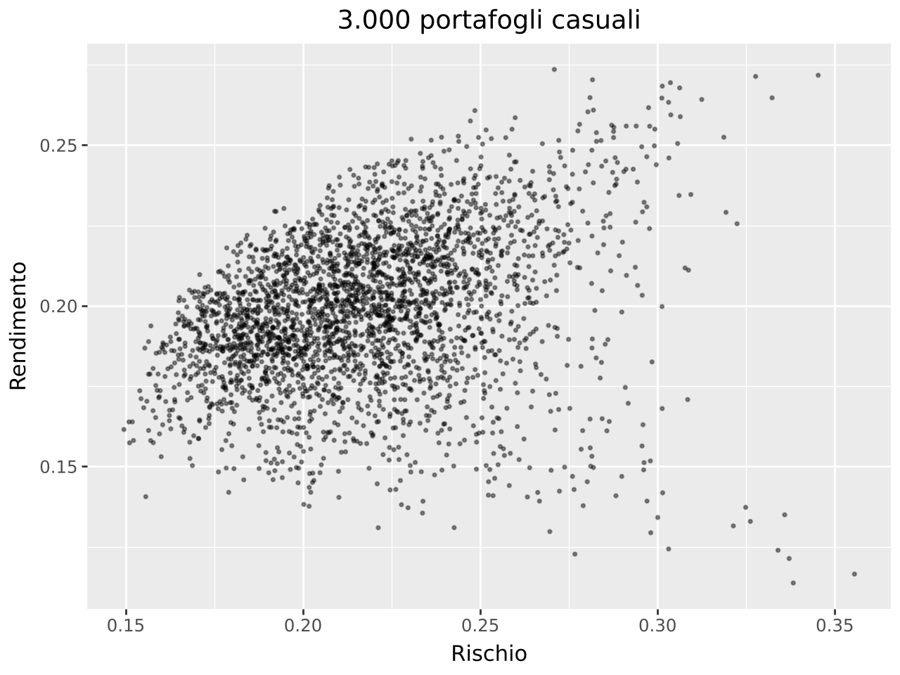

In [44]:
#ogni punto è un portafoglio: a destra più rischio, in alto più rendimento
ggplot(portafogli, aes(x="rischio", y="rendimento"))+geom_point(size=0.5, alpha=0.4)+labs(x="Rischio", y="Rendimento", title="3.000 portafogli casuali")

## 9 · La frontiera efficiente

Un portafoglio è **efficiente** se nessun altro rende di più con un rischio uguale o minore. Per trovarli: mettiamo i portafogli in ordine di rischio e teniamo quelli che rendono più di tutti i precedenti.

In [45]:
#cum_max è il rendimento più alto visto fin lì, andando dal meno al più rischioso
#un portafoglio è efficiente se il suo rendimento è proprio quel massimo
frontiera = portafogli.sort("rischio").with_columns(massimo=pl.col("rendimento").cum_max()).filter(pl.col("rendimento") == pl.col("massimo"))
frontiera.height #40 portafogli efficienti su 3.000

40

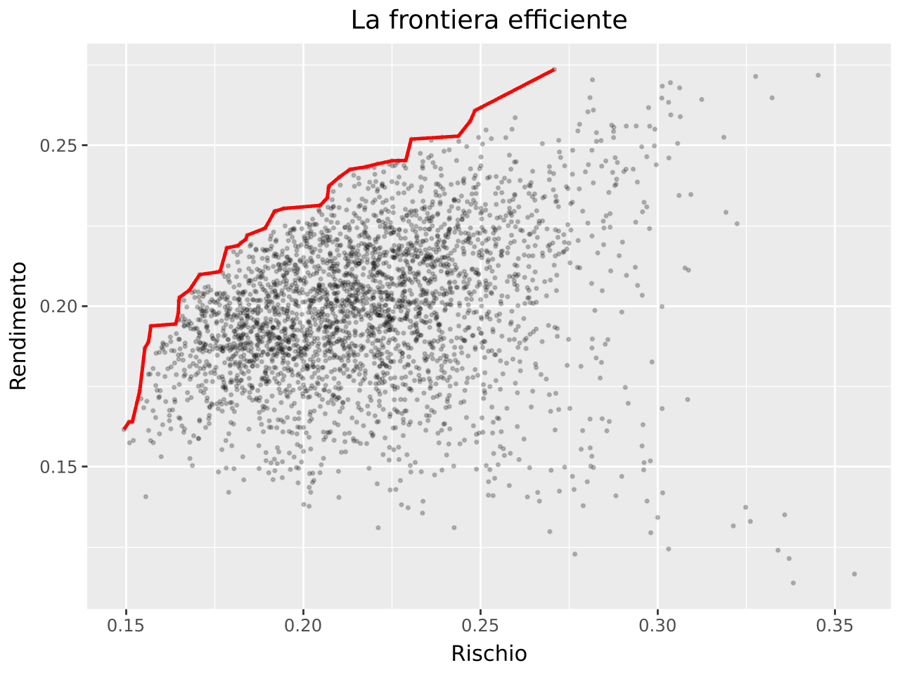

In [46]:
#la linea rossa unisce i 40 portafogli efficienti: è la frontiera, il bordo in alto a sinistra della nuvola
#tutti gli altri punti stanno sotto o a destra: si può avere più rendimento con lo stesso rischio
ggplot(portafogli, aes(x="rischio", y="rendimento"))+geom_point(size=0.5, alpha=0.2)+geom_line(data=frontiera, color="red", size=1)+labs(x="Rischio", y="Rendimento", title="La frontiera efficiente")

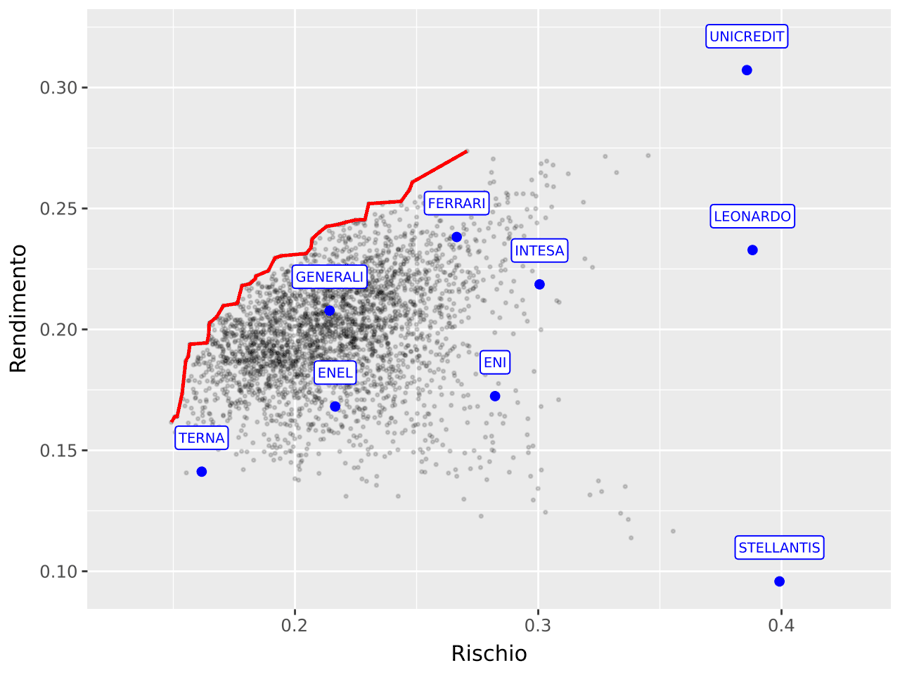

In [47]:
#i titoli da soli (senza l'indice) sopra la nuvola: stanno quasi tutti lontano dalla linea rossa
soli = titoli.filter(pl.col("titolo") != "FTSEMIB")
ggplot(portafogli, aes(x="rischio", y="rendimento"))+geom_point(size=0.5, alpha=0.15)+geom_line(data=frontiera, color="red", size=1)+geom_point(data=soli, color="blue", size=2)+geom_label(aes(label="titolo"), data=soli, color="blue", size=7, nudge_y=0.014)+xlim(0.13, 0.43)+labs(x="Rischio", y="Rendimento")

In [48]:
#quanti portafogli hanno meno rischio di ENI (28,2%) e insieme più rendimento (17,2%)? 2.550 su 3.000
#vale per otto titoli su nove; l'eccezione è Unicredit, il titolo che ha reso di più: nessun portafoglio lo supera
portafogli.filter(pl.col("rischio") <= 0.282, pl.col("rendimento") >= 0.172).height

2550

## 10 · Quale portafoglio scegliere?

Due candidati sulla frontiera: il portafoglio con il **rischio minimo** e quello con il miglior rapporto tra rendimento e rischio, l'**indice di Sharpe**:

$$\text{Sharpe} = \frac{\mu_p - r_f}{\sigma_p}$$

Come tasso senza rischio $r_f$ ipotizziamo il 2,5% l'anno.

In [49]:
#il meno rischioso dei 3.000: rischio 14,9%, meno di qualunque titolo da solo (Terna, il più tranquillo, ha 16,2%)
portafogli.sort("rischio").head(1)

portafoglio,rendimento,rischio
i64,f64,f64
1184,0.161486,0.149471


In [50]:
#i suoi pesi: è il portafoglio numero 1184, letto nella tabella sopra. Terna fa il 72%
pesi.filter(pl.col("portafoglio") == 1184).select("titolo", "peso").sort("peso", descending=True)

titolo,peso
str,f64
"""TERNA""",0.722951
"""FERRARI""",0.079857
"""GENERALI""",0.067015
"""INTESA""",0.066793
"""LEONARDO""",0.041369
"""STELLANTIS""",0.01894
"""ENEL""",0.001966
"""ENI""",0.00111
"""UNICREDIT""",2.9552e-8


In [51]:
#Sharpe: quanto rendimento in più del tasso senza rischio per ogni punto di rischio
portafogli = portafogli.with_columns(sharpe=(pl.col("rendimento")-0.025)/pl.col("rischio"))
portafogli.sort("sharpe", descending=True).head(1) #rendimento 21,8%, rischio 17,8%, Sharpe 1,08

portafoglio,rendimento,rischio,sharpe
i64,f64,f64,f64
678,0.217999,0.178476,1.081375


In [52]:
#i pesi del portafoglio numero 678: Ferrari 39%, Generali 25%, Terna 20%, Unicredit 12%; gli altri quasi zero
pesi.filter(pl.col("portafoglio") == 678).select("titolo", "peso").sort("peso", descending=True)

titolo,peso
str,f64
"""FERRARI""",0.388268
"""GENERALI""",0.246186
"""TERNA""",0.199004
"""UNICREDIT""",0.120819
"""LEONARDO""",0.03246
"""STELLANTIS""",0.007398
"""ENI""",0.005535
"""ENEL""",0.000326
"""INTESA""",0.000002


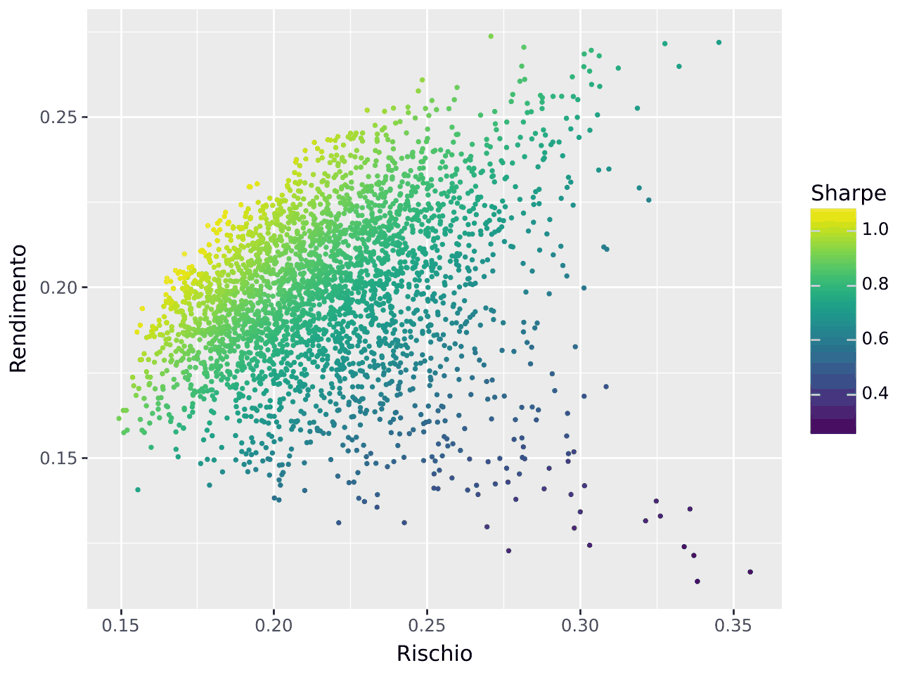

In [53]:
#la nuvola colorata con lo Sharpe: i più chiari sono i migliori, lungo la frontiera
ggplot(portafogli, aes(x="rischio", y="rendimento", color="sharpe"))+geom_point(size=0.5)+labs(x="Rischio", y="Rendimento", color="Sharpe")

## Facoltativo A · Il portafoglio migliore resta il migliore?

Finora abbiamo scelto guardando tutti i dieci anni. Chi investe però conosce solo il passato. Dividiamo i dati in due: scegliamo il portafoglio con i **primi cinque anni** e vediamo come va nei **cinque successivi**. I 3.000 portafogli (i pesi) sono gli stessi.

In [54]:
#prima: dicembre 2016 - novembre 2021 (60 mesi). dopo: dicembre 2021 - ottobre 2026 (59 mesi)
prima = lungo.filter(pl.col("data") < pl.date(2021, 12, 1))
dopo = lungo.filter(pl.col("data") >= pl.date(2021, 12, 1))

In [55]:
#i titoli nei due periodi: Ferrari da 34% a 13%, Stellantis da 32% a -13%, Leonardo da -5% a 52%
r_prima = prima.group_by("titolo").agg(rendimento_prima=pl.col("rendimento").mean()*12, rischio_prima=pl.col("rendimento").std()*12**0.5)
r_dopo = dopo.group_by("titolo").agg(rendimento_dopo=pl.col("rendimento").mean()*12, rischio_dopo=pl.col("rendimento").std()*12**0.5)
r_prima.join(r_dopo, on="titolo").sort("rischio_prima")

titolo,rendimento_prima,rischio_prima,rendimento_dopo,rischio_dopo
str,f64,f64,f64,f64
"""TERNA""",0.15171,0.167315,0.130299,0.157638
"""FTSEMIB""",0.107667,0.215118,0.145445,0.158625
"""ENEL""",0.185755,0.238188,0.15002,0.194455
"""GENERALI""",0.165573,0.238282,0.25043,0.188465
"""FERRARI""",0.342829,0.257211,0.131537,0.274711
"""ENI""",0.076528,0.29846,0.269713,0.264678
"""INTESA""",0.123818,0.341554,0.31479,0.252454
"""LEONARDO""",-0.045529,0.414388,0.515603,0.344065
"""UNICREDIT""",0.107917,0.415147,0.509529,0.347348


In [56]:
#gli stessi passi della parte 8, in fila, solo sui primi cinque anni
#le parentesi esterne servono per andare a capo
p_prima = (
    pesi.join(prima, on="titolo")
    .with_columns(contributo=pl.col("peso")*pl.col("rendimento"))
    .group_by("portafoglio", "data").agg(rendimento=pl.col("contributo").sum())
    .group_by("portafoglio").agg(rendimento=pl.col("rendimento").mean()*12, rischio=pl.col("rendimento").std()*12**0.5)
    .with_columns(sharpe=(pl.col("rendimento")-0.025)/pl.col("rischio"))
)

In [57]:
#e sui cinque anni successivi
p_dopo = (
    pesi.join(dopo, on="titolo")
    .with_columns(contributo=pl.col("peso")*pl.col("rendimento"))
    .group_by("portafoglio", "data").agg(rendimento=pl.col("contributo").sum())
    .group_by("portafoglio").agg(rendimento=pl.col("rendimento").mean()*12, rischio=pl.col("rendimento").std()*12**0.5)
    .with_columns(sharpe=(pl.col("rendimento")-0.025)/pl.col("rischio"))
)

In [58]:
#le due tabelle affiancate: le colonne del secondo periodo finiscono con _dopo
confronto = p_prima.join(p_dopo, on="portafoglio", suffix="_dopo")
confronto.sort("portafoglio").head()

portafoglio,rendimento,rischio,sharpe,rendimento_dopo,rischio_dopo,sharpe_dopo
i64,f64,f64,f64,f64,f64,f64
0,0.121328,0.255227,0.377419,0.314597,0.162876,1.778026
1,0.195833,0.275674,0.61969,0.141002,0.20247,0.572932
2,0.221352,0.180629,1.087046,0.165884,0.154342,0.912802
3,0.142627,0.25487,0.461516,0.307492,0.170851,1.653436
4,0.228014,0.199568,1.017267,0.15368,0.160814,0.800183


In [59]:
#il migliore dei primi cinque anni: rendimento 26,8%, rischio 18,8%, Sharpe 1,29
#nei cinque anni dopo: rendimento 10,5%, rischio 17,8%, Sharpe 0,45
confronto.sort("sharpe", descending=True).head(1)

portafoglio,rendimento,rischio,sharpe,rendimento_dopo,rischio_dopo,sharpe_dopo
i64,f64,f64,f64,f64,f64,f64
2077,0.267718,0.187888,1.291822,0.104675,0.177513,0.448842


In [60]:
#i suoi pesi (portafoglio 2077): metà Ferrari, un terzo Terna, 13% Stellantis. Erano i titoli saliti di più fino al 2021
pesi.filter(pl.col("portafoglio") == 2077).select("titolo", "peso").sort("peso", descending=True)

titolo,peso
str,f64
"""FERRARI""",0.496552
"""TERNA""",0.331243
"""STELLANTIS""",0.130395
"""INTESA""",0.012269
"""GENERALI""",0.011881
"""UNICREDIT""",0.008985
"""ENEL""",0.006924
"""LEONARDO""",0.001242
"""ENI""",0.000508


In [61]:
#quanti dei 3.000 portafogli hanno fatto meglio di lui nel secondo periodo? 2.854: è finito tra gli ultimi
confronto.filter(pl.col("sharpe_dopo") > 0.45).height

2854

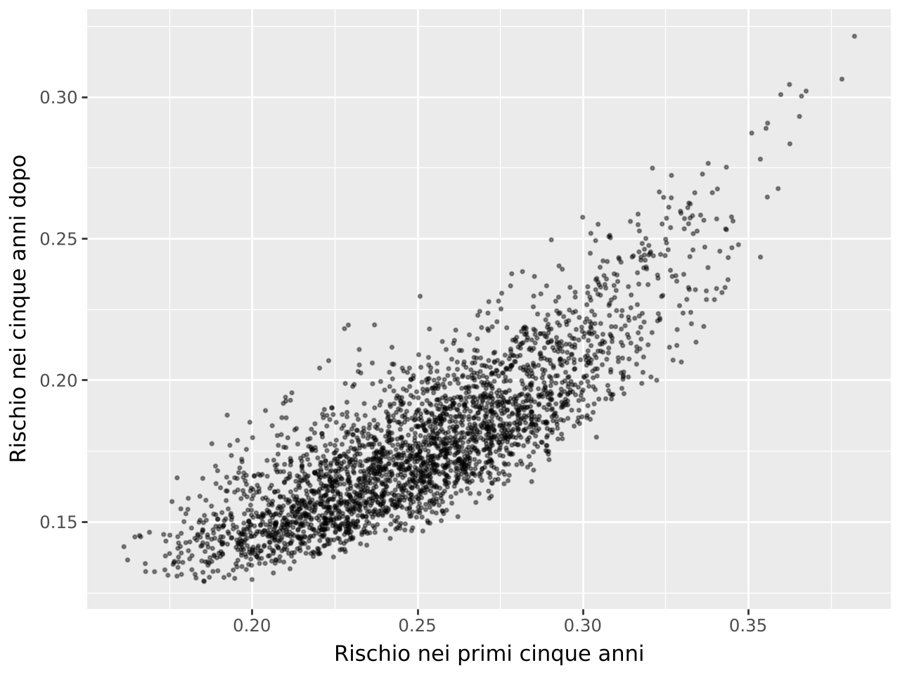

In [62]:
#il rischio prima e dopo: i punti stanno lungo una retta. Chi era rischioso è rimasto rischioso
ggplot(confronto, aes(x="rischio", y="rischio_dopo"))+geom_point(size=0.5, alpha=0.4)+labs(x="Rischio nei primi cinque anni", y="Rischio nei cinque anni dopo")

In [63]:
confronto.select(pl.corr("rischio", "rischio_dopo")) #correlazione 0,84

rischio
f64
0.841959


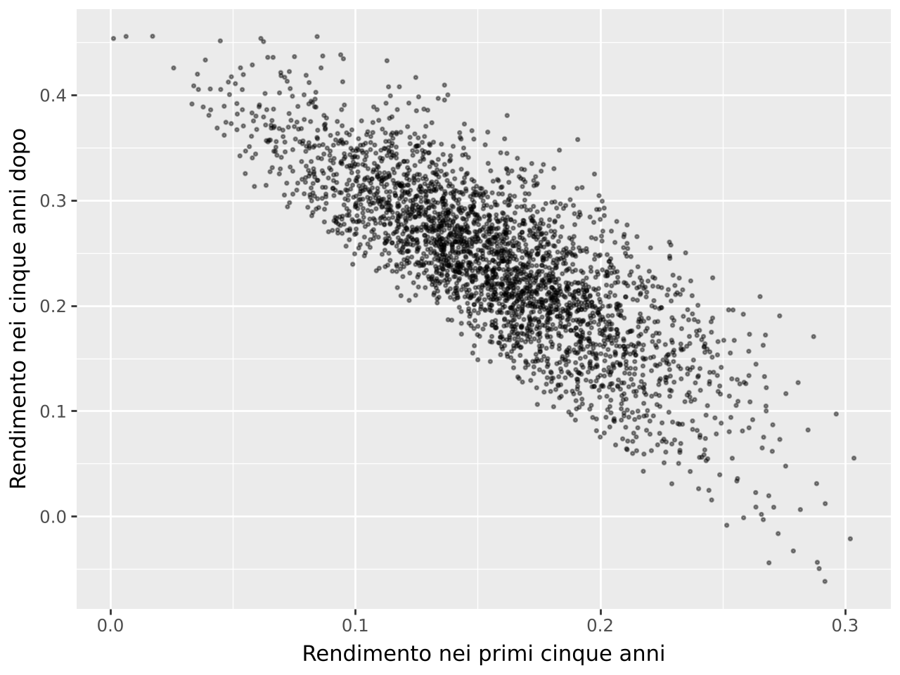

In [64]:
#il rendimento prima e dopo: la nuvola scende. Chi aveva reso di più ha poi reso di meno
ggplot(confronto, aes(x="rendimento", y="rendimento_dopo"))+geom_point(size=0.5, alpha=0.4)+labs(x="Rendimento nei primi cinque anni", y="Rendimento nei cinque anni dopo")

In [65]:
confronto.select(pl.corr("rendimento", "rendimento_dopo")) #correlazione -0,81

rendimento
f64
-0.813742


In [66]:
#e il portafoglio a rischio minimo dei primi cinque anni? rischio 16,1% prima, 14,1% dopo: è rimasto tra i più tranquilli
confronto.sort("rischio").head(1)

portafoglio,rendimento,rischio,sharpe,rendimento_dopo,rischio_dopo,sharpe_dopo
i64,f64,f64,f64,f64,f64,f64
1341,0.170607,0.161308,0.902661,0.143841,0.14114,0.842008


**Cosa abbiamo visto.** In questi dati il rischio del passato dice molto sul rischio futuro, il rendimento del passato no. Per questo il portafoglio a rischio minimo ha tenuto, mentre quello a Sharpe massimo, che dipende dai rendimenti medi, no. Il modello media-varianza serve a ragionare su rischio e diversificazione, non a prevedere quale titolo salirà.

## Facoltativo B · Un ponte con la regressione: il beta

Quanto si muove un titolo quando si muove il mercato? È una regressione lineare: y è il rendimento del titolo, x il rendimento dell'indice. La pendenza si chiama **beta**:

$$r_{\text{titolo}} = \alpha + \beta\, r_{\text{mercato}} + \epsilon$$

In [67]:
import statsmodels.formula.api as smf #modelli statistici: la regressione

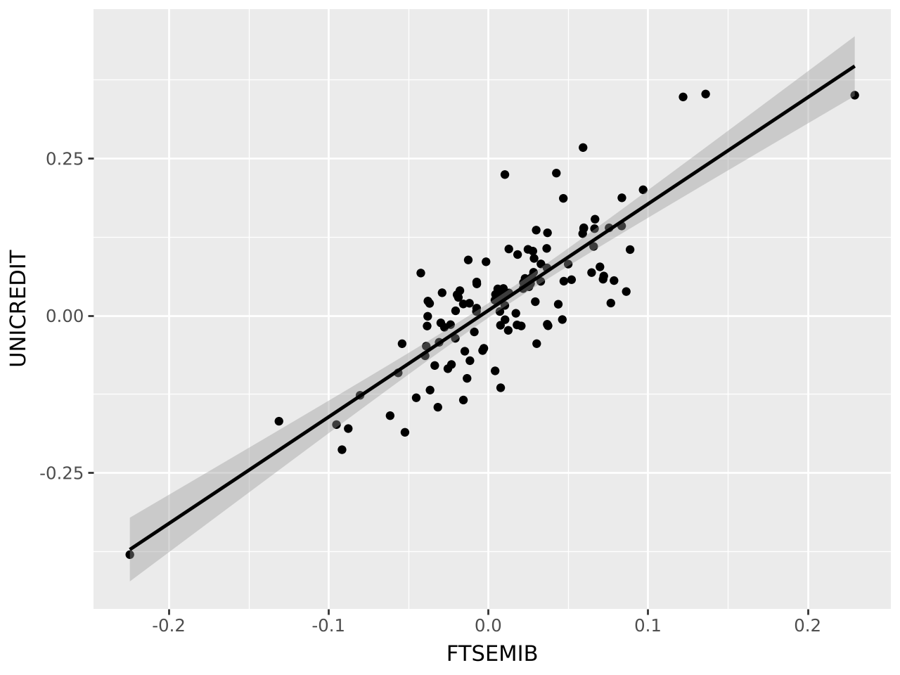

In [68]:
#ogni punto è un mese: quando l'indice sale, Unicredit sale di più
ggplot(rendimenti, aes(x="FTSEMIB", y="UNICREDIT"))+geom_point()+geom_smooth(method="lm")

In [69]:
modello = smf.ols("UNICREDIT ~ FTSEMIB", data=rendimenti).fit()

In [70]:
#FTSEMIB 1,69: se l'indice fa +1%, Unicredit in media fa +1,69%. Beta > 1: amplifica il mercato
#p-value 0,000: significativo. R² 0,69: il mercato spiega il 69% delle oscillazioni del titolo
#Durbin-Watson 2,00 (in basso a destra): vicino a 2 vuol dire che gli errori di un mese non dipendono dal mese prima
modello.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:              UNICREDIT   R-squared:                       0.685
Model:                            OLS   Adj. R-squared:                  0.683
Method:                 Least Squares   F-statistic:                     254.8
Date:                Tue, 24 Nov 2026   Prob (F-statistic):           3.73e-31
Time:                        14:40:02   Log-Likelihood:                 161.63
No. Observations:                 119   AIC:                            -319.3
Df Residuals:                     117   BIC:                            -313.7
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.0077      0.006      1.321      0.189      -0.004       0.019
FTSEMIB        1.6944      0.106     15.963      0.000       1.484       1.905
==============================================================================
Omnibus:                        2.907   Durbin-Watson:                   1.995
Prob(Omnibus):                  0.234   Jarque-Bera (JB):                2.349
Skew:                           0.313   Prob(JB):                        0.309
Kurtosis:                       3.287   Cond. No.                         18.5
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [71]:
#Terna: beta 0,41, molto minore di 1. Un titolo difensivo, si muove meno della metà del mercato
#p-value 0,000: significativo. R² 0,22: gran parte delle sue oscillazioni non dipende dal mercato
modello2 = smf.ols("TERNA ~ FTSEMIB", data=rendimenti).fit()
modello2.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  TERNA   R-squared:                       0.223
Model:                            OLS   Adj. R-squared:                  0.216
Method:                 Least Squares   F-statistic:                     33.52
Date:                Tue, 24 Nov 2026   Prob (F-statistic):           6.03e-08
Time:                        14:40:02   Log-Likelihood:                 211.14
No. Observations:                 119   AIC:                            -418.3
Df Residuals:                     117   BIC:                            -412.7
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.0075      0.004      1.937      0.055      -0.000       0.015
FTSEMIB        0.4054      0.070      5.790      0.000       0.267       0.544
==============================================================================
Omnibus:                        0.620   Durbin-Watson:                   2.319
Prob(Omnibus):                  0.734   Jarque-Bera (JB):                0.740
Skew:                          -0.153   Prob(JB):                        0.691
Kurtosis:                       2.765   Cond. No.                         18.5
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

### Sono dati nel tempo: la regressione si può fare?

Sui **rendimenti** sì: oscillano intorno a una media stabile e un mese non dipende quasi dal precedente. Sui **prezzi** no: crescono nel tempo, e due serie che crescono sembrano legate anche quando non lo sono. Proviamo con ENI e Ferrari, che abbiamo visto essere quasi incorrelate (0,10).

In [72]:
#sui prezzi: R² 0,41 e p-value 0,000. Sembra una relazione forte, ma è solo che entrambi i prezzi sono saliti
#Durbin-Watson 0,08, lontanissimo da 2: è il segnale che la regressione non è affidabile
smf.ols("FERRARI ~ ENI", data=prezzi).fit().summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                FERRARI   R-squared:                       0.413
Model:                            OLS   Adj. R-squared:                  0.408
Method:                 Least Squares   F-statistic:                     82.99
Date:                Tue, 24 Nov 2026   Prob (F-statistic):           2.54e-15
Time:                        14:40:02   Log-Likelihood:                -706.09
No. Observations:                 120   AIC:                             1416.
Df Residuals:                     118   BIC:                             1422.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     35.4238     21.186      1.672      0.097      -6.529      77.377
ENI           16.9625      1.862      9.110      0.000      13.275      20.650
==============================================================================
Omnibus:                        7.691   Durbin-Watson:                   0.084
Prob(Omnibus):                  0.021   Jarque-Bera (JB):                7.171
Skew:                           0.534   Prob(JB):                       0.0277
Kurtosis:                       2.458   Cond. No.                         30.3
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [73]:
#sui rendimenti: R² 0,01 e p-value 0,282. Nessuna relazione, come diceva la correlazione
#Durbin-Watson 2,18: vicino a 2
smf.ols("FERRARI ~ ENI", data=rendimenti).fit().summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                FERRARI   R-squared:                       0.010
Model:                            OLS   Adj. R-squared:                  0.001
Method:                 Least Squares   F-statistic:                     1.170
Date:                Tue, 24 Nov 2026   Prob (F-statistic):              0.282
Time:                        14:40:02   Log-Likelihood:                 137.38
No. Observations:                 119   AIC:                            -270.8
Df Residuals:                     117   BIC:                            -265.2
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.0185      0.007      2.582      0.011       0.004       0.033
ENI            0.0940      0.087      1.082      0.282      -0.078       0.266
==============================================================================
Omnibus:                        1.395   Durbin-Watson:                   2.182
Prob(Omnibus):                  0.498   Jarque-Bera (JB):                1.033
Skew:                           0.218   Prob(JB):                        0.597
Kurtosis:                       3.136   Cond. No.                         12.3
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

## Da dove arrivano i dati (facoltativo)

Il file `ftsemib.csv` è stato scaricato da Yahoo Finance con il pacchetto `yfinance`. Per scaricare altri titoli basta cambiare i codici: quelli di Borsa Italiana finiscono con `.MI`. `yfinance` restituisce una tabella di pandas, che `pl.from_pandas` trasforma in polars.

**Attenzione.** Yahoo limita le richieste: se in tanti scaricano insieme, un titolo può tornare vuoto (tutti `null`) con l'avviso rosso *Too Many Requests*, senza un vero errore. Si riprova dopo qualche minuto. Per il laboratorio usiamo il CSV, che non ha questo problema.

In [74]:
import yfinance as yf
yahoo = yf.download(["ENI.MI", "RACE.MI"], start="2016-10-29", end="2026-11-01", interval="1mo", auto_adjust=True, progress=False)["Close"]
yahoo = pl.from_pandas(yahoo.reset_index())
yahoo.head()

Crumb fetch rate-limited (HTTP 429), continuing without crumb


Date,ENI.MI,RACE.MI
datetime[ms],f64,f64
2016-11-01 00:00:00,7.113403,47.873665
2016-12-01 00:00:00,8.374762,51.207226
2017-01-01 00:00:00,7.692656,53.429607
2017-02-01 00:00:00,7.860474,56.948364
2017-03-01 00:00:00,8.309798,64.587776


In [75]:
#quanti mesi mancano per ogni titolo: se un titolo ha 120 null, Yahoo l'ha bloccato e va riscaricato
yahoo.null_count()

Date,ENI.MI,RACE.MI
u32,u32,u32
0,0,0
